# 03 · End-to-End HM-QCT Key Exchange

Part of the project *Simulating Hidden-Matching-Based Hybrid Quantum Key Distribution in Qiskit*.

This notebook combines the classical and quantum layers into a complete key exchange, following the protocol structure of HM-QCT (Mazzoncini et al., *Quantum* 9, 1862, 2025):

1. **Classical layer.** Alice sends the βPM data $(M, \omega)$ for every round to Bob under AES-256-GCM.
2. **Quantum layer.** Alice sends $m$ copies of $|\psi_x\rangle$ per round over a lossy, noisy channel, and Bob performs the matching measurement.
3. **Post-processing.** Sifting, QBER estimation, error correction, verification and privacy amplification.

It also produces Figure 4 (QBER vs. channel noise) and Figure 5 (sifted rate vs. fibre distance).

## Setup

In [1]:
!pip install -q qiskit qiskit-aer matplotlib pylatexenc cryptography

In [2]:
import os, json, hashlib
import numpy as np
import matplotlib.pyplot as plt

import qiskit
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import DiagonalGate, UnitaryGate
from qiskit_aer import AerSimulator
from cryptography.hazmat.primitives.ciphers.aead import AESGCM

print("Qiskit version:", qiskit.__version__)
sim = AerSimulator()

Qiskit version: 2.6.2


## 1. Hidden Matching components

The circuit-level functions are carried over from notebook 02 unchanged, apart from an optional channel step between Alice and Bob (Section 2).

In [3]:
def random_perfect_matching(n, rng):
    perm = rng.permutation(n)
    return [(int(perm[2 * t]), int(perm[2 * t + 1])) for t in range(n // 2)]


def complete_matching(partial, n):
    used = {v for e in partial for v in e}
    rest = [v for v in range(n) if v not in used]
    return list(partial) + [(rest[2 * t], rest[2 * t + 1]) for t in range(len(rest) // 2)]


def alice_circuit(x):
    n = len(x)
    k = int(np.log2(n))
    qc = QuantumCircuit(k, k)
    qc.h(range(k))
    qc.append(DiagonalGate([(-1.0) ** int(b) for b in x]), range(k))
    return qc


def matching_permutation(matching, n):
    P = np.zeros((n, n))
    for t, (i, j) in enumerate(matching):
        P[2 * t, i] = 1
        P[2 * t + 1, j] = 1
    return P


def add_matching_measurement(qc, matching, n):
    k = qc.num_qubits
    qc.barrier()
    qc.append(UnitaryGate(matching_permutation(matching, n), label="Perm(M)"), range(k))
    qc.h(0)
    qc.measure(range(k), range(k))
    return qc


def decode(bitstring):
    r = int(bitstring, 2)
    return r >> 1, r & 1


def bpm_instance(n, beta, rng):
    x = rng.integers(0, 2, n)
    M = random_perfect_matching(n, rng)[: int(beta * n)]
    a = int(rng.integers(0, 2))
    omega = np.array([x[i] ^ x[j] ^ a for (i, j) in M])
    return x, M, omega, a

## 2. Channel model

**Loss.** Each copy reaches Bob independently with probability $\eta$. For optical fibre, $\eta = 10^{-\alpha L / 10}$ with $\alpha = 0.2$ dB/km.

**Noise.** Arriving copies pass through a $k$-qubit depolarizing channel $\rho \mapsto (1-p)\rho + p\, I/2^k$. It is simulated by Monte Carlo: with probability $p$ a uniformly random $k$-qubit Pauli is applied, since averaging over all $4^k$ Paulis gives the maximally mixed state. A depolarized copy yields a uniformly random outcome, so its parity is wrong half the time:

$$\text{QBER} = p/2.$$

With loss, Bob's per-round success probability becomes $1 - (1 - 2\beta\eta)^m$.

In [4]:
def apply_depolarizing(qc, p, rng):
    # Monte Carlo sample of a k-qubit depolarizing channel
    if rng.random() < p:
        for q in range(qc.num_qubits):
            pauli = rng.integers(0, 4)   # 0 = I, 1 = X, 2 = Y, 3 = Z
            if pauli == 1:
                qc.x(q)
            elif pauli == 2:
                qc.y(q)
            elif pauli == 3:
                qc.z(q)
    return qc


def fibre_transmittance(L_km, alpha_db_per_km=0.2):
    return 10 ** (-alpha_db_per_km * L_km / 10)

## 3. Classical layer: encrypting $(M, \omega)$

Alice and Bob share a 256-bit key used for AES-GCM. In a deployment this key could come from a post-quantum KEM such as ML-KEM; here it is simply pre-shared. The QCT assumption is that this encryption stays secure for longer than any eavesdropper's quantum memory remains coherent, so Eve has to measure her copies without knowing $M$.

In [5]:
def encrypt_rounds(rounds, psk):
    payload = json.dumps([{"M": M, "omega": omega.tolist()} for (x, M, omega, a) in rounds]).encode()
    nonce = os.urandom(12)
    return nonce, AESGCM(psk).encrypt(nonce, payload, None)


def decrypt_rounds(nonce, ciphertext, psk):
    data = json.loads(AESGCM(psk).decrypt(nonce, ciphertext, None))
    return [([tuple(e) for e in r["M"]], np.array(r["omega"])) for r in data]

## 4. Post-processing

- **Parameter estimation.** A random 10% of the sifted bits is disclosed to estimate the QBER and then discarded.
- **Error correction.** A simplified Cascade: parity checks on blocks of size $\approx 0.73/\text{QBER}$, with a binary search inside each mismatched block. Passes are repeated on shuffled copies of the key until three consecutive passes find no error (at most 20). Every disclosed parity counts as leaked information. Stopping on clean passes, rather than after a fixed number, matters because the sampled QBER can underestimate the true one, which makes the blocks too large.
- **Verification.** Alice and Bob compare SHA-256 hashes of their corrected keys.
- **Privacy amplification.** A random Toeplitz matrix compresses the key to

$$\ell = \left\lfloor N\, H_{\min} - \text{leak}_{\text{EC}} - 2\log_2(1/\varepsilon_{\text{PA}}) \right\rfloor,$$

with $H_{\min} = -\log_2 P_{\text{guess}}$ per bit.

**Caveat.** For $P_{\text{guess}}$ we use the heuristic attack from notebook 02, so the final key length is illustrative only. A rigorous key length requires the general guessing-probability bound proved in the paper.

In [6]:
def parity(bits):
    return int(np.sum(bits) % 2)


def binary_search_fix(alice, bob, idx):
    # locate and flip one error in a block with mismatched parity
    leaked = 0
    while len(idx) > 1:
        half = idx[: len(idx) // 2]
        leaked += 1
        if parity(alice[half]) != parity(bob[half]):
            idx = half
        else:
            idx = idx[len(idx) // 2 :]
    bob[idx[0]] ^= 1
    return leaked


def error_correct(alice, bob, qber_est, rng, max_passes=20, clean_passes=3):
    # simplified Cascade without backtracking: shuffled passes of block parity
    # checks + binary search, repeated until clean_passes in a row find no error.
    # Both parities are computed locally here; in practice Alice announces hers
    # over the authenticated channel, so every comparison counts as leaked.
    bob = bob.copy()
    N = len(alice)
    block = max(4, int(0.73 / max(qber_est, 1e-3)))
    leaked, clean = 0, 0
    for p in range(max_passes):
        order = np.arange(N) if p == 0 else rng.permutation(N)
        found = 0
        for start in range(0, N, block):
            idx = order[start : start + block]
            leaked += 1
            if parity(alice[idx]) != parity(bob[idx]):
                leaked += binary_search_fix(alice, bob, idx)
                found += 1
        clean = clean + 1 if found == 0 else 0
        if clean >= clean_passes:
            break
    return bob, leaked


def key_hash(bits):
    return hashlib.sha256(np.packbits(bits.astype(np.uint8)).tobytes()).hexdigest()


def toeplitz_hash(bits, out_len, rng):
    # out_len x N Toeplitz matrix from N + out_len - 1 public random bits
    N = len(bits)
    r = rng.integers(0, 2, N + out_len - 1)
    i, j = np.indices((out_len, N))
    T = r[i - j + N - 1]
    return (T @ bits) % 2


def eve_guess_heuristic(n, beta, m):
    return 0.5 + 0.5 * (1 - (1 - 2 * beta / (n - 1)) ** m)

## 5. Full protocol

In [7]:
def run_hmqct(n=32, beta=0.25, m=4, n_rounds=2000, eta=1.0, p_noise=0.0,
              eps_pa=1e-6, seed=7, verbose=True):
    rng = np.random.default_rng(seed)
    log = print if verbose else (lambda *a, **k: None)

    # 1. Alice generates βPM instances
    rounds = [bpm_instance(n, beta, rng) for _ in range(n_rounds)]
    a_bits = np.array([r[3] for r in rounds])

    # 2. classical layer: Enc(M, omega) -> Bob
    psk = AESGCM.generate_key(bit_length=256)
    nonce, ct = encrypt_rounds(rounds, psk)
    bob_data = decrypt_rounds(nonce, ct, psk)
    assert all(M == r[1] and np.array_equal(w, r[2]) for (M, w), r in zip(bob_data, rounds))
    log(f"[classical] AES-GCM ciphertext: {len(ct)} bytes, decrypted by Bob")

    # 3. quantum layer: m copies per round, loss + depolarizing noise
    circuits, owner = [], []
    for r, (x, _, _, _) in enumerate(rounds):
        M_full = complete_matching(bob_data[r][0], n)
        for _ in range(m):
            if rng.random() < eta:                       # copy survives the channel
                qc = alice_circuit(x)
                qc.barrier()
                apply_depolarizing(qc, p_noise, rng)
                circuits.append(add_matching_measurement(qc, M_full, n))
                owner.append(r)
    log(f"[quantum] {len(circuits)} of {n_rounds * m} copies arrived")

    bob_bits = np.full(n_rounds, -1)
    if circuits:
        result = sim.run(transpile(circuits, sim), shots=1, memory=True,
                         seed_simulator=seed).result()
        for c, r in enumerate(owner):
            if bob_bits[r] != -1:
                continue                                  # round already decoded
            t, par = decode(result.get_memory(c)[0])
            M, omega = bob_data[r]
            if t < len(M):
                bob_bits[r] = par ^ omega[t]

    # 4. sifting
    kept = bob_bits != -1
    A, B = a_bits[kept], bob_bits[kept].astype(int)
    log(f"[sifting] kept {kept.sum()} / {n_rounds} rounds "
        f"(theory {1 - (1 - 2 * beta * eta) ** m:.3f})")
    out = {"sifted": int(kept.sum()), "sift_rate": kept.mean(),
           "qber_true": float(np.mean(A != B)) if len(A) else float("nan")}
    if len(A) < 50:
        log("[abort] too few sifted bits")
        out["final_len"] = 0
        return out

    # 5. parameter estimation on a disclosed random sample
    sample = rng.random(len(A)) < 0.1
    qber_est = float(np.mean(A[sample] != B[sample]))
    A, B = A[~sample], B[~sample]
    out["qber_est"] = qber_est
    log(f"[estimation] QBER estimate {qber_est:.4f} (true {out['qber_true']:.4f}, "
        f"theory {p_noise / 2:.4f})")

    # 6. error correction + verification
    B_corr, leaked = error_correct(A, B, qber_est, rng)
    match = key_hash(A) == key_hash(B_corr)
    out.update({"leaked": leaked, "residual_errors": int(np.sum(A != B_corr)), "verified": match})
    log(f"[error correction] {leaked} parity bits disclosed, "
        f"residual errors {out['residual_errors']}, hashes match: {match}")
    if not match:
        log("[abort] verification failed")
        out["final_len"] = 0
        return out

    # 7. privacy amplification
    N = len(A)
    h_min = -np.log2(eve_guess_heuristic(n, beta, m))
    ell = int(np.floor(N * h_min - leaked - 2 * np.log2(1 / eps_pa)))
    out.update({"h_min": h_min, "final_len": max(ell, 0)})
    if ell <= 0:
        log(f"[abort] no extractable key (N = {N}, H_min = {h_min:.3f}, leak = {leaked})")
        return out

    pa_seed = int(rng.integers(0, 2**31))
    K_alice = toeplitz_hash(A, ell, np.random.default_rng(pa_seed))
    K_bob = toeplitz_hash(B_corr, ell, np.random.default_rng(pa_seed))
    assert np.array_equal(K_alice, K_bob)
    out["key"] = K_alice
    log(f"[privacy amplification] H_min = {h_min:.3f} bits/bit, final key length {ell} bits")
    log(f"[result] shared key (first 64 bits, hex): {np.packbits(K_alice[:64]).tobytes().hex()}")
    return out

### 5.1 Example run

$n = 32$ (5 qubits), $\beta = 1/4$, $m = 4$ copies, 2000 rounds, no loss, depolarizing probability $p = 0.04$ (expected QBER 2%).

In [8]:
res = run_hmqct(n=32, beta=0.25, m=4, n_rounds=2000, eta=1.0, p_noise=0.04)

[classical] AES-GCM ciphertext: 237958 bytes, decrypted by Bob
[quantum] 8000 of 8000 copies arrived
[sifting] kept 1858 / 2000 rounds (theory 0.938)
[estimation] QBER estimate 0.0169 (true 0.0242, theory 0.0200)
[error correction] 512 parity bits disclosed, residual errors 0, hashes match: True
[privacy amplification] H_min = 0.912 bits/bit, final key length 981 bits
[result] shared key (first 64 bits, hex): ddce2d25df08a361


## 6. QBER vs. channel noise (Figure 4)

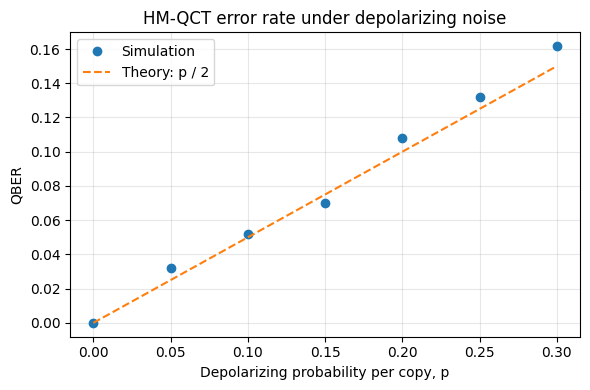

p = 0.00   QBER = 0.000   theory = 0.000
p = 0.05   QBER = 0.032   theory = 0.025
p = 0.10   QBER = 0.052   theory = 0.050
p = 0.15   QBER = 0.070   theory = 0.075
p = 0.20   QBER = 0.108   theory = 0.100
p = 0.25   QBER = 0.132   theory = 0.125
p = 0.30   QBER = 0.162   theory = 0.150


In [9]:
p_values = np.linspace(0, 0.3, 7)
qber_sim = [run_hmqct(n=16, beta=0.25, m=2, n_rounds=600, p_noise=p,
                      seed=200 + i, verbose=False)["qber_true"]
            for i, p in enumerate(p_values)]

plt.figure(figsize=(6, 4))
plt.plot(p_values, qber_sim, "o", label="Simulation")
plt.plot(p_values, p_values / 2, "--", label="Theory: p / 2")
plt.xlabel("Depolarizing probability per copy, p")
plt.ylabel("QBER")
plt.title("HM-QCT error rate under depolarizing noise")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("fig4_qber_vs_noise.png", dpi=200)
plt.show()

for p, q in zip(p_values, qber_sim):
    print(f"p = {p:.2f}   QBER = {q:.3f}   theory = {p / 2:.3f}")

## 7. Sifted rate vs. fibre distance (Figure 5)

Sifted bits per round for HM-QCT with $m$ copies, $1 - (1-2\beta\eta)^m$, compared with an ideal single-photon BB84 source, $\eta/2$. Simulated points are shown at short distances. For $\beta = 1/4$ and $m = 1$ the two expressions coincide ($2\beta\eta = \eta/2$), so a single copy matches BB84 and the gain comes entirely from sending more copies.

**Caveat.** This compares *sifted* rates, not secret key rates. The secret key rate also depends on the eavesdropper bound, which weakens as $m$ grows, so this figure shows the effect of multiple copies on loss tolerance, not a security claim.

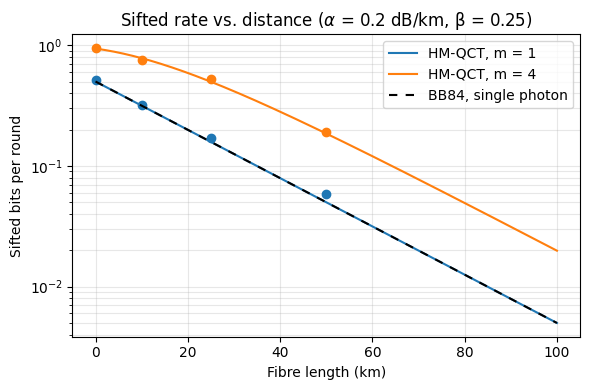

In [10]:
L = np.linspace(0, 100, 200)
eta_L = fibre_transmittance(L)
beta = 0.25

plt.figure(figsize=(6, 4))
for m, c in [(1, "tab:blue"), (4, "tab:orange")]:
    plt.semilogy(L, 1 - (1 - 2 * beta * eta_L) ** m, color=c, label=f"HM-QCT, m = {m}")
    L_pts = [0, 10, 25, 50]
    sim_pts = [run_hmqct(n=16, beta=beta, m=m, n_rounds=800, eta=fibre_transmittance(d),
                         seed=300 + m * 10 + d, verbose=False)["sift_rate"] for d in L_pts]
    plt.semilogy(L_pts, sim_pts, "o", color=c)
plt.semilogy(L, eta_L / 2, "k--", dashes=(4, 4), zorder=5, label="BB84, single photon")
plt.xlabel("Fibre length (km)")
plt.ylabel("Sifted bits per round")
plt.title(r"Sifted rate vs. distance ($\alpha$ = 0.2 dB/km, β = 0.25)")
plt.legend()
plt.grid(alpha=0.3, which="both")
plt.tight_layout()
plt.savefig("fig5_sifted_rate_vs_distance.png", dpi=200)
plt.show()

## 8. Discussion

- The full pipeline runs end to end: the matching data is protected by AES-GCM, Bob decodes the quantum states using it, and after post-processing Alice and Bob hold identical keys.
- The QBER follows $p/2$ under depolarizing noise, as predicted.
- Sending $m$ copies raises the sifted rate roughly $m$-fold at long distance, which single-photon BB84 cannot do safely.

**Limitations.**
- The key length uses a heuristic eavesdropper bound and is illustrative only; the paper's general bound is needed for a security claim.
- Finite-size effects, detector imperfections and authentication of the classical channel are not modelled.
- The error correction is a simplified Cascade and is not optimised for leakage.
- System sizes are limited to $n \le 32$ (5 qubits) by simulation cost; the asymptotic advantage claimed in the paper needs much larger $n$.